# Лабораторная №4. Байесовская сеть для кошек из приюта

Исследуем завершённые случаи в приюте Остина за октябрь 2013 — май 2025 года. Одна строка — один исход одного обращения. Одна кошка может встречаться несколько раз. [Открытые данные города Остина](https://data.austintexas.gov/Health-and-Community-Services/Austin-Animal-Center-Outcomes-10-01-2013-to-05-05-/9t4d-g238)

| Узел | Состояние 1 | Состояние 0 |
|---|---|---|
| `Kitten` | Младше года на момент исхода | Год и старше |
| `Male` | Самец | Самка |
| `Black` | Окрас записан ровно как Black | Любая другая запись об окрасе |
| `Adopted` | Исход Adoption | Другой известный исход |

## 1. Подготовка данных

Возраст в днях, неделях, месяцах и годах переводим в дни и делим по границе в год. Записи о стерилизованных и нестерилизованных животных объединяем по полу. Редкие окрасы входят в общую группу остальных.

Удаляем полные повторы в выгрузке, записи с неизвестным полом, пропусками исхода или окраса, а также отсутствующим или некорректным возрастом. Разные обращения одного животного сохраняем. Внутри состояния 0 у `Adopted` остаются перевод в другую организацию, возврат владельцу и другие исходы.


In [1]:
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

path = Path("data/austin-cats.csv")
if not path.exists():
    path = Path("bayesian") / path
raw = pd.read_csv(path)
display(raw.isna().sum().rename("Пропуски"))
display(raw["outcome_type"].value_counts().rename("Исходы"))

records = raw.drop_duplicates()
age = records["age_upon_outcome"].str.extract(r"^(\d+) (day|week|month|year)s?$")
days = age[0].astype(float) * age[1].map({"day": 1, "week": 7, "month": 365 / 12, "year": 365})
sex = records["sex_upon_outcome"].str.split().str[-1]
valid = days.notna() & sex.isin(["Male", "Female"])
valid &= records[["color", "outcome_type"]].notna().all(axis=1)

data = pd.DataFrame({
    "Kitten": days.loc[valid] < 365,
    "Male": sex.loc[valid] == "Male",
    "Black": records.loc[valid, "color"].eq("Black"),
    "Adopted": records.loc[valid, "outcome_type"] == "Adoption",
}).astype(int)
print("Исходных строк:", len(raw), "| Повторов:", len(raw) - len(records))
print("Неизвестный пол:", (~sex.isin(["Male", "Female"])).sum())
print("Возраст пропущен или некорректен:", days.isna().sum())
print("Осталось строк:", len(data))
display(pd.DataFrame({"Состояние 0": (data == 0).sum(),
                      "Состояние 1": data.sum(), "Число состояний": data.nunique()}))
display(data.groupby(["Kitten", "Male", "Black"]).size().rename("Число случаев"))

animal_id           0
datetime            0
outcome_type        9
age_upon_outcome    4
sex_upon_outcome    0
color               0
Name: Пропуски, dtype: int64

outcome_type
Adoption           35781
Transfer           26702
Return to Owner     2868
Euthanasia          2563
Died                1006
Rto-Adopt            249
Disposal             164
Missing               51
Relocate               6
Name: Исходы, dtype: int64

Исходных строк: 69399 | Повторов: 12
Неизвестный пол: 5012
Возраст пропущен или некорректен: 5
Осталось строк: 64362


,Состояние 0,Состояние 1,Число состояний
Kitten,22269,42093,2
Male,32533,31829,2
Black,56228,8134,2
Adopted,28588,35774,2


Kitten  Male  Black
0       0     0        10726
              1         1174
        1     0         9005
              1         1364
1       0     0        18222
              1         2411
        1     0        18275
              1         3185
Name: Число случаев, dtype: int64


## 2. Вопросы к сети

1. Как меняется вероятность пристройства, если известно, что это котёнок?
2. Какова эта вероятность для чёрного котёнка?
3. Как меняется вероятность пристройства, если известен только чёрный окрас?
4. Если известно, что кошку пристроили, какова вероятность, что это котёнок?

Последовательно добавим возраст, пол и окрас и проследим распределение исхода.

## 3. Структура сети

Узлы возраста, пола и окраса направлены к пристройству. Возраст может быть связан с выбором посетителей и особенностями ухода. Пол также может учитываться при выборе, хотя в эту переменную не входит статус стерилизации. Окрас виден посетителям, поэтому допускаем связь с выбором животного. Эти соображения задаём до оценки вероятностей и затем проверяем на данных.

Направления выбраны, чтобы описывать исход при известных характеристиках кошки. Возраст указан на момент исхода. Граф представляет наблюдаемые связи и допускает пересчёт вероятностей в обратном направлении.

Все стрелки входят в `Adopted`, поэтому граф является DAG. Корневые переменные считаются взаимно независимыми. Кроме того, их связь с пристройством может отражать другие обстоятельства, например состояние здоровья и условия работы приюта.

$$P(K,M,B,A)=P(K)P(M)P(B)P(A\mid K,M,B).$$

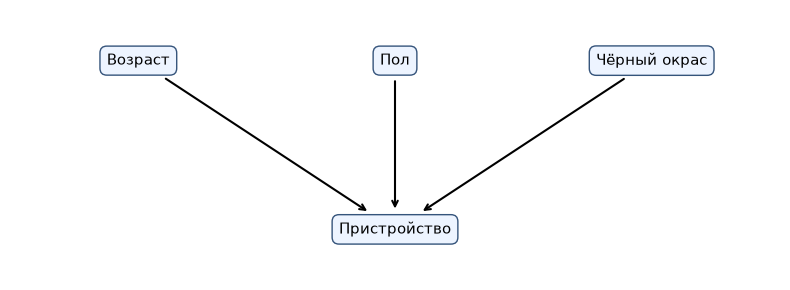

In [2]:
fig, ax = plt.subplots(figsize=(8, 3))
positions = {"Возраст": (0, 1), "Пол": (1, 1), "Чёрный окрас": (2, 1), "Пристройство": (1, 0)}
labels = {}
for name, (x, y) in positions.items():
    labels[name] = ax.text(x, y, name, ha="center", va="center", fontsize=11,
                           bbox={"boxstyle": "round,pad=0.45", "fc": "#edf4ff", "ec": "#35547b"})
ax.set(xlim=(-0.5, 2.5), ylim=(-0.3, 1.3))
ax.axis("off")
fig.canvas.draw()
for start in ["Возраст", "Пол", "Чёрный окрас"]:
    ax.annotate("", xy=positions["Пристройство"], xytext=positions[start],
                arrowprops={"arrowstyle": "->", "lw": 1.5, "shrinkA": 4, "shrinkB": 4,
                            "patchA": labels[start].get_bbox_patch(),
                            "patchB": labels["Пристройство"].get_bbox_patch()})
plt.tight_layout()
plt.show()

## 4. Таблицы вероятностей

In [3]:
parents = ["Kitten", "Male", "Black"]
roots = data[parents].mean()

def conditional_table(adoption_parents):
    return data.groupby(adoption_parents)["Adopted"].agg(count="size", p1="mean")

adoption_cpt = conditional_table(parents)
display(pd.DataFrame({"P(0)": 1 - roots, "P(1)": roots}).round(4))
display(adoption_cpt.assign(p0=1 - adoption_cpt["p1"]).round(4))
display(data[parents].corr().round(3))

def joint_table(adoption_parents):
    states = pd.DataFrame(product([0, 1], repeat=4), columns=parents + ["Adopted"])
    outcome = conditional_table(adoption_parents)
    assert len(outcome) == 2 ** len(adoption_parents)
    states = states.join(outcome["p1"], on=adoption_parents)
    mass = pd.Series(1.0, index=states.index)
    for name in parents:
        mass *= states[name].map({0: 1 - roots[name], 1: roots[name]})
    states["P"] = mass * states["p1"].where(states["Adopted"] == 1, 1 - states["p1"])
    assert states["P"].between(0, 1).all()
    assert abs(states["P"].sum() - 1) < 1e-10
    return states

joint = joint_table(parents)

,P(0),P(1)
Kitten,0.3460,0.6540
Male,0.5055,0.4945
Black,0.8736,0.1264


count      p1      p0
Kitten Male Black                       
0      0    0      10726  0.4444  0.5556
            1       1174  0.4174  0.5826
       1    0       9005  0.4177  0.5823
            1       1364  0.4084  0.5916
1      0    0      18222  0.6299  0.3701
            1       2411  0.6114  0.3886
       1    0      18275  0.6214  0.3786
            1       3185  0.5937  0.4063

,Kitten,Male,Black
Kitten,1.000,0.042,0.027
Male,0.042,1.000,0.049
Black,0.027,0.049,1.000


**Проверка таблиц.** Среди котят-самок без чёрного окраса Adoption встречается в 62.99% случаев, а с чёрным окрасом — в 61.14%. У котят-самцов соответствующие доли равны 62.14% и 59.37%. Для взрослых групп получаем 40.84–44.44%. Разница по возрасту здесь заметнее различий по полу и окрасу. 
Парные корреляции трёх двоичных признаков малы (0.027–0.049), что согласуется с приближённостью допущения о независимости.

## 5. Запросы и последовательное добавление evidence



,Событие,"P до, %","P после, %","Разница, п.п.","Доля в данных, %",Случаев
Сведения,,,,,,
Котёнок,Adopted,55.57,62.28,6.71,62.24,42093
Чёрный котёнок,Adopted,55.57,60.26,4.69,60.13,5596
Чёрный окрас,Adopted,55.57,53.70,-1.87,54.24,8134
Возраст при известном пристройстве,Kitten,65.40,73.30,7.90,73.23,35774


,"Пристройство, %","Другой исход, %","Изменение, п.п."
Ничего не известно,55.57,44.43,NaN
Котёнок,62.28,37.72,6.71
"Котёнок, самец",61.79,38.21,-0.49
"Котёнок, самец, чёрный",59.37,40.63,-2.42


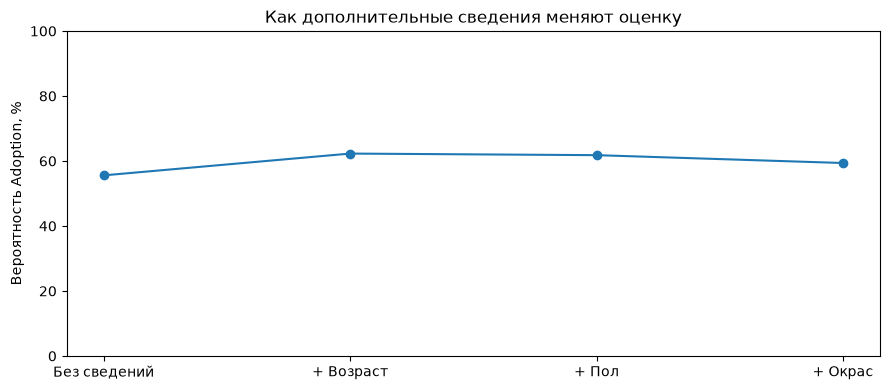

In [4]:
def select(table, evidence):
    for name, value in evidence.items():
        table = table.loc[table[name] == value]
    return table

def probability(table, event, evidence):
    matching = select(table, evidence)
    return matching.loc[matching[event] == 1, "P"].sum() / matching["P"].sum()

queries = [
    ("Котёнок", "Adopted", {"Kitten": 1}),
    ("Чёрный котёнок", "Adopted", {"Kitten": 1, "Black": 1}),
    ("Чёрный окрас", "Adopted", {"Black": 1}),
    ("Возраст при известном пристройстве", "Kitten", {"Adopted": 1}),
]
rows = []
for label, event, evidence in queries:
    observed = select(data, evidence)
    before = probability(joint, event, {})
    after = probability(joint, event, evidence)
    rows.append({
        "Сведения": label, "Событие": event, "P до, %": 100 * before,
        "P после, %": 100 * after, "Разница, п.п.": 100 * (after - before),
        "Доля в данных, %": 100 * observed[event].mean(), "Случаев": len(observed),
    })
answers = pd.DataFrame(rows).set_index("Сведения")
display(answers.round(2))

evidence_steps = {
    "Ничего не известно": {},
    "Котёнок": {"Kitten": 1},
    "Котёнок, самец": {"Kitten": 1, "Male": 1},
    "Котёнок, самец, чёрный": {"Kitten": 1, "Male": 1, "Black": 1},
}
steps = pd.DataFrame({
    "Пристройство, %": {label: 100 * probability(joint, "Adopted", evidence)
                       for label, evidence in evidence_steps.items()}
})
steps["Другой исход, %"] = 100 - steps["Пристройство, %"]
steps["Изменение, п.п."] = steps["Пристройство, %"].diff()
display(steps.round(2))
ax = steps["Пристройство, %"].plot(
    marker="o", figsize=(9, 4), ylim=(0, 100), ylabel="Вероятность Adoption, %",
    title="Как дополнительные сведения меняют оценку",
)
ax.set_xticks(range(4), ["Без сведений", "+ Возраст", "+ Пол", "+ Окрас"], rotation=0)
plt.tight_layout()
plt.show()

**Ответы на вопросы.** Без сведений вероятность Adoption по сети равна 55.57%. Для котёнка она равна 62.28%, для чёрного котёнка — 60.26%, а при одном известном чёрном окрасе — 53.70%. 

В обратном запросе интересующее событие - возраст. До получения сведений вероятность котёнка равна 65.40%. После сообщения об Adoption она равна 73.30%. Это результат байесовского обновления в той же сети. 

При последовательном добавлении сведений получаем 55.57% → 62.28% → 61.79% → 59.37%. Возраст повышает оценку, пол и чёрный окрас в выбранной группе её снижают. Все три признака являются родителями исхода. Когда известны все три, остаётся одна строка условной таблицы, и 59.37% совпадает с долей Adoption в этой группе. 

## 6. Изменение структуры

Удаляем `Kitten → Adopted` и заново оцениваем таблицу пристройства только по полу и окрасу. Повторяем первый запрос про котёнка, сравнивая обе сети. После удаления ребра возраст становится изолированным узлом. Полученная факторизация предполагает независимость возраста и пристройства.

In [5]:
reduced = joint_table(["Male", "Black"])
rows = []
for label, table in {"Исходная сеть": joint, "Без ребра от возраста": reduced}.items():
    before = probability(table, "Adopted", {})
    after = probability(table, "Adopted", {"Kitten": 1})
    rows.append({"Сеть": label, "P до, %": 100 * before,
                 "P для котёнка, %": 100 * after,
                 "Изменение, п.п.": round(100 * (after - before), 4) + 0.0})
comparison = pd.DataFrame(rows).set_index("Сеть")
display(comparison.round(2))
assert abs(probability(reduced, "Adopted", {"Kitten": 1}) - probability(reduced, "Adopted", {})) < 1e-10

,"P до, %","P для котёнка, %","Изменение, п.п."
Сеть,,,
Исходная сеть,55.57,62.28,6.71
Без ребра от возраста,55.58,55.58,0.00


## 7. Выводы

Сеть позволила ответить на четыре вопроса и проследить обновление полного распределения бинарного исхода. Возраст даёт наиболее заметное изменение среди рассмотренных запросов. Знание Adoption, в свою очередь, повышает оценку вероятности котёнка с 65.40% до 73.30%.

Удаление ребра от возраста исключает его из таблицы исхода. В исходной сети вероятность пристройства меняется с 55.57% до 62.28% при известном возрасте котёнка. В изменённой сети оба значения равны 55.58%. 

Сеть описывает завершённые обращения в одном приюте. Возраст измерен при исходе, разные обращения одной кошки могут зависеть друг от друга. Исключены записи с неизвестным полом и другими недостаточными сведениями. Здоровье, срок пребывания и обстоятельства поступления не учтены. Группировка окраса и возраста упрощает данные.

Корневые переменные считаются взаимно независимыми. Направления рёбер заданы для описания исхода при известных характеристиках. Построенную сеть нельзя считать подтверждённой причинной моделью. Например, из меньшей вероятности Adoption у чёрных кошек в модели не следует, что изменение цвета у той же кошки изменило бы исход. Для причинного утверждения нужны дополнительные предположения о механизмах и факторах смешения или данные подходящего эксперимента.